Talking about measurement error
https://youtu.be/R1vcdhPBlXA?t=5008




In [8]:
# Generative simulation
# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-02?slide=53
# https://youtu.be/R1vcdhPBlXA?t=2497
# for a given set of parameters, produces a sample
import numpy as np
import pandas as pd

def sim_globe2(p=0.7, N=9, x=0.1, rng=None):
    """
    p: proportion of the globe covered by water. 0 <= p <= 1
    N: number of tosses
    x: measurement error; .1 == 10% will record opposite of true 
    "W": water; "L": land.
    replace=True: each toss is independent.
    """
    if rng is None:
        rng = np.random.default_rng()

    true_sample = rng.choice(
        ["W", "L"],
        size=N,
        p=[p, 1 - p]
    )

    errors = rng.uniform(size=N) < x

    obs_sample = np.where(
        errors,
        np.where(true_sample == "W", "L", "W"),
        true_sample
    )

    return obs_sample

# now we test it
rng = np.random.default_rng(42)

print(sim_globe2(p=1, N=11, x=0, rng=rng))
print(sim_globe2(p=0, N=11, x=0, rng=rng))
print(sim_globe2(p=1, N=11, x=1, rng=rng))
print(sim_globe2(p=0, N=11, x=0.5, rng=rng))
# large N
print( sum( [v == 'W' for v in sim_globe2(p=0.5, N=int(1e4), x=0, rng=rng) ] ) / 1e4 )

print( sum( [v == 'W' for v in sim_globe2(p=0.5, N=int(1e4), x=0.3, rng=rng) ] ) / 1e4 )



['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W']
['L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L']
['L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L']
['L' 'L' 'L' 'L' 'W' 'L' 'W' 'W' 'W' 'L' 'W']
0.5009
0.5008


$$
Pr(water \mid p,x) = p(1-x) + (1-p)x
\\
Pr(land \mid p,x) = (1-p)(1-x)
\\[2em]



\begin{aligned}
P(W_{\mathrm{obs}}\mid p,x)
&= p(1-x)+(1-p)x \\[0.5em]
P(L_{\mathrm{obs}}\mid p,x)
&= (1-p)(1-x)+px \\[2em]
P(p\mid W,L,x)
&=
\frac{
\overbrace{[p(1-x)+(1-p)x]^W}^{\text{probability of observing } W}
\times
\overbrace{[(1-p)(1-x)+px]^L}^{\text{probability of observing } L}
}{    
    {\underbrace{Z}_{\text{some unpleasant normalizing constant}}}
}
\end{aligned}


$$

Z is the normalizing constant, number total ways

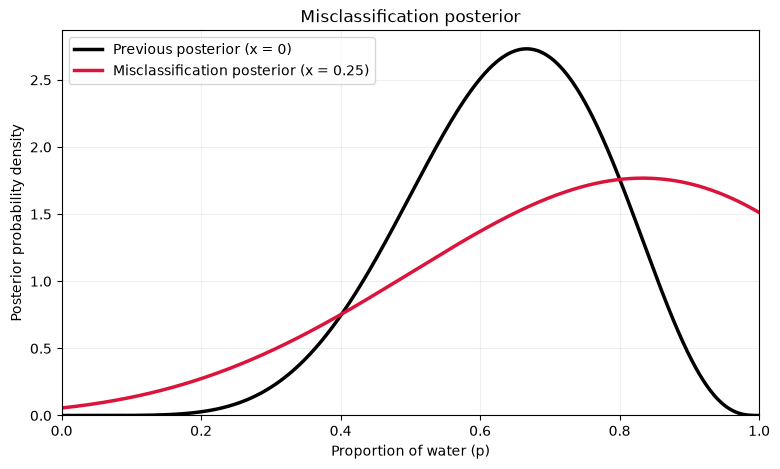

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Observed data
W = 6
L = 3

#W = 60
#L = 30

# Misclassification probability
x = 0.25

# Values of p to evaluate
p = np.linspace(0, 1, 1000)

# Original posterior: no misclassification (x = 0)
posterior_original = beta.pdf(p, W + 1, L + 1)

# Posterior with misclassification
prob_water = p * (1 - x) + (1 - p) * x
prob_land = (1 - p) * (1 - x) + p * x

likelihood = prob_water**W * prob_land**L

# Uniform prior, so posterior is proportional to likelihood
posterior_misclass = likelihood / np.trapezoid(likelihood, p)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(
    p, posterior_original,
    color="black",
    linewidth=2.5,
    label="Previous posterior (x = 0)"
)

plt.plot(
    p, posterior_misclass,
    color="crimson",
    linewidth=2.5,
    label=f"Misclassification posterior (x = {x})"
)

plt.xlabel("Proportion of water (p)")
plt.ylabel("Posterior probability density")
plt.title("Misclassification posterior")

plt.xlim(0, 1)
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.2)

plt.show()